In [182]:
with open("/kaggle/input/datasets/raaggeesingh/verdict-sample-dataset/the_verdict.txt", "r") as f:
    raw_text = f.read()
print(raw_text[:100])
print(f"Total Chars: {len(raw_text)}")

I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no g
Total Chars: 20479


In [183]:
import torch.nn as nn

## Simple tokenization process

In [184]:
import re
def simple_tokenization(txt):
    return re.split(r'([,.:;?_!"()\']|--|\s)', txt)

In [185]:
res = simple_tokenization(raw_text)
res = [item for item in res if item.strip()]

In [186]:
print(len(res))
print(res[:10])

4690
['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius']


In [187]:
all_words = sorted(res)

In [188]:
print(len(all_words))

4690


In [189]:
vocab = {token:pos for pos, token in enumerate(all_words)}

In [190]:
inverse_vocab = {pos:token for pos, token in enumerate(all_words)}

In [191]:
class Tokenizer:
    def __init__(self, file_path):
        self.file_path = file_path
        self.str_to_int = None
        self.int_to_str = None
        self.text = None
        self.split = None

    def open_file(self):
        with open(self.file_path, "r") as f:
            self.text = f.read()

    def create_vocab(self):
        res = re.split(r'([,.:;?_!"()\']|--|\s)', self.text)
        self.split = [item for item in res if item.strip()]
        self.str_to_int = {token: pos for pos, token in enumerate(res)}

    def encoder(self):
        self.open_file()
        self.create_vocab()
        ids = [self.str_to_int[s] for s in self.split]
        return ids

    def decode(self, ids):
        self.int_to_str = {v:k for k, v in self.str_to_int.items()}
        print(self.int_to_str)
        text = " ".join(self.int_to_str[i] for i in ids)
        return text

In [192]:
toke = Tokenizer("/kaggle/input/datasets/raaggeesingh/verdict-sample-dataset/the_verdict.txt")

In [193]:
encoded = toke.encoder()

In [194]:
# toke.decode([2, 18])

## Simple Tokenizer v2

In [195]:
with open("/kaggle/input/datasets/raaggeesingh/verdict-sample-dataset/the_verdict.txt", "r") as f:
    raw_text = f.read()
print(raw_text[:100])
print(f"Total Chars: {len(raw_text)}")

I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no g
Total Chars: 20479


In [196]:
res = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
res = [item for item in res if item.strip()]
sorted_res = sorted(res)
sorted_res.extend(["<|endoftext|>", "<|unk|>"])
processed = {token:pos for pos, token in enumerate(sorted_res)}

In [197]:
class SimpleTokenizer:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {v:k for k,v in self.str_to_int.items()}

    def encode(self, text):
        processed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        processed = [item for item in processed if item.strip()]
        processed = [item if item in self.str_to_int else "<|unk|>" for item in processed]
        ids = [self.str_to_int[i] for i in processed]
        return ids

    def decode(self, ids):
        # print(self.int_to_str)
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text


In [198]:
text1 = "Hey! Whats up?"
text2 = "He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture."
text = "<|endoftext|>".join((text1, text2))

In [199]:
text

'Hey! Whats up?<|endoftext|>He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.'

In [200]:
token2 = SimpleTokenizer(processed)
res = token2.encode(text)
print(res)

[4691, 23, 4691, 4394, 865, 4691, 3450, 4141, 1672, 3098, 2064, 1595, 1886, 4316, 4421, 4394, 1595, 2037, 4131, 3564, 489, 3799, 3158, 1595, 4144, 1765, 4131, 3438, 798]


In [201]:
token2.decode(res)

'<|unk|>! <|unk|> up? <|unk|> placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.'

## BPE

In [202]:
import tiktoken

In [203]:
tokenizer = tiktoken.get_encoding("gpt2")

In [204]:
text = (
    "Hello!<|endoftext|>This is Raaggee Singh.<|endoftext|>I am here."
)

In [205]:
tokenize = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

In [206]:
tokenize

[15496,
 0,
 50256,
 1212,
 318,
 7567,
 363,
 29622,
 14403,
 13,
 50256,
 40,
 716,
 994,
 13]

In [207]:
tokenizer.decode(tokenize)

'Hello!<|endoftext|>This is Raaggee Singh.<|endoftext|>I am here.'

## Data Sampling with Sliding Window

In [208]:
with open("/kaggle/input/datasets/raaggeesingh/verdict-sample-dataset/the_verdict.txt", "r") as f:
    raw_text = f.read()

toke = SimpleTokenizer(vocab)
enc_text = toke.encode(raw_text)
print(len(enc_text))

4690


In [209]:
context_size = 10
x = enc_text[:context_size]
y = enc_text[context_size+1]

In [210]:
for i in range(1, context_size+1):
    x = enc_text[:i]
    y = enc_text[i]
    print(f"{x} ----> {y}")

[1098] ----> 950
[1098, 950] ----> 1501
[1098, 950, 1501] ----> 4191
[1098, 950, 1501, 4191] ----> 1132
[1098, 950, 1501, 4191, 1132] ----> 940
[1098, 950, 1501, 4191, 1132, 940] ----> 3525
[1098, 950, 1501, 4191, 1132, 940, 3525] ----> 1421
[1098, 950, 1501, 4191, 1132, 940, 3525, 1421] ----> 1847
[1098, 950, 1501, 4191, 1132, 940, 3525, 1421, 1847] ----> 2243
[1098, 950, 1501, 4191, 1132, 940, 3525, 1421, 1847, 2243] ----> 586


In [211]:
for i in range(1, context_size+1):
    x = enc_text[:i]
    y = [enc_text[i]]
    print(f"{toke.decode(x)} ----> {toke.decode(y)}")

I ----> HAD
I HAD ----> always
I HAD always ----> thought
I HAD always thought ----> Jack
I HAD always thought Jack ----> Gisburn
I HAD always thought Jack Gisburn ----> rather
I HAD always thought Jack Gisburn rather ----> a
I HAD always thought Jack Gisburn rather a ----> cheap
I HAD always thought Jack Gisburn rather a cheap ----> genius
I HAD always thought Jack Gisburn rather a cheap genius ----> --


# Loading data effectively

In [212]:
import torch
from torch.utils.data import DataLoader, Dataset

In [213]:
class GPTDatasetV1(Dataset):
    def __init__(self, tokenizer, max_length, stride, txt):
        self.input_ids = []
        self.target_ids = []

        token_ids = toke.encode(txt)

        for i in range(0, len(token_ids)-max_length, stride):
            input_chunk = token_ids[i:i+max_length]
            target_chunk = token_ids[i+1:i+max_length+1]
            self.input_ids.append(input_chunk)
            self.target_ids.append(target_chunk)

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [214]:
data = GPTDatasetV1(toke, 10, 4, raw_text)

In [215]:
toke.decode(data[11][0])

'rich widow, and established himself in a villa on'

In [216]:
toke.decode(data[11][1])

'widow, and established himself in a villa on the'

## Creating a Dataloader for loading tokens from GPTTokenizerV1

In [217]:
def create_dataloader_v1(txt, batch_size, stride=128, max_length=256, shuffle=True, drop_last=True):
    toke = SimpleTokenizer(vocab)
    dataset = GPTDatasetV1(toke, max_length, stride, txt)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        drop_last=drop_last,
    )
    return dataloader

In [218]:
data_iter=iter(create_dataloader_v1(raw_text, 4, 2, 4))
first = next(data_iter)
print(first[0][0])

tensor([1098, 1501, 1132, 3525])


In [219]:
toke.decode(first[0][0].to(torch.int32).tolist())

'I always Jack rather'

In [220]:
toke.decode(first[0][1].to(torch.int32).tolist())


'HAD thought Gisburn a'

In [221]:
input, target = next(data_iter)

In [222]:
toke.decode(input[0].to(torch.int32).tolist())

'cheap -- a fellow'

In [223]:
toke.decode(target[0].to(torch.int32).tolist())


'genius though good enough'

## Creating embeddings

In [224]:
## sample
input_ids = torch.tensor([2, 3, 4, 1])
vocab_size=6
output_dim=4

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

print(embedding_layer.weight)


Parameter containing:
tensor([[ 0.3374, -0.1778, -0.3035, -0.5880],
        [ 0.3486,  0.6603, -0.2196, -0.3792],
        [-0.1606, -0.4015,  0.6957, -1.8061],
        [ 1.8960, -0.1750,  1.3689, -1.6033],
        [-0.7849, -1.4096, -0.4076,  0.7953],
        [ 0.9985,  0.2212,  1.8319, -0.3378]], requires_grad=True)


In [225]:
print(embedding_layer(torch.tensor([3])))

tensor([[ 1.8960, -0.1750,  1.3689, -1.6033]], grad_fn=<EmbeddingBackward0>)


In [226]:
print(embedding_layer(torch.tensor(input_ids)))


tensor([[-0.1606, -0.4015,  0.6957, -1.8061],
        [ 1.8960, -0.1750,  1.3689, -1.6033],
        [-0.7849, -1.4096, -0.4076,  0.7953],
        [ 0.3486,  0.6603, -0.2196, -0.3792]], grad_fn=<EmbeddingBackward0>)


/tmp/ipykernel_58/3823692661.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  print(embedding_layer(torch.tensor(input_ids)))


# Embeddings for raw_text

In [227]:
vocab_size=4690
output_dim=256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [228]:
max_length=4
dataloader = create_dataloader_v1(raw_text, batch_size=8, stride=max_length, max_length=max_length)
data_iter = iter(dataloader)
inputs, output = next(data_iter)

In [229]:
input_tensor = torch.stack(input)
input_tensor

tensor([[1847,  586, 1421, 2154],
        [2243, 4183, 2275, 2081],
        [ 586, 1421, 2154,  586],
        [4183, 2275, 2081, 3766]])

In [230]:
token_embeddings = token_embedding_layer(torch.tensor(input_tensor))
token_embeddings

/tmp/ipykernel_58/939471641.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  token_embeddings = token_embedding_layer(torch.tensor(input_tensor))


tensor([[[-0.0327, -0.3413,  1.7113,  ...,  1.7646,  0.4831,  0.4341],
         [-0.6606, -0.7655, -0.2341,  ...,  0.9074, -0.5273,  2.3616],
         [-0.9489, -0.2425,  1.4251,  ...,  0.7475, -0.1101,  0.0748],
         [-0.9689,  1.4538,  0.3748,  ..., -1.1705,  0.3230,  1.6235]],

        [[-1.1400, -0.0290, -0.3162,  ..., -0.3906,  1.0162, -0.3007],
         [-0.2530, -1.8211,  0.7243,  ...,  0.5066,  1.3517,  2.0515],
         [-2.4705, -0.4957, -0.8820,  ...,  0.1865, -0.5145, -1.3625],
         [ 0.2772, -0.5328,  0.0193,  ..., -1.4298, -0.9085, -0.1301]],

        [[-0.6606, -0.7655, -0.2341,  ...,  0.9074, -0.5273,  2.3616],
         [-0.9489, -0.2425,  1.4251,  ...,  0.7475, -0.1101,  0.0748],
         [-0.9689,  1.4538,  0.3748,  ..., -1.1705,  0.3230,  1.6235],
         [-0.6606, -0.7655, -0.2341,  ...,  0.9074, -0.5273,  2.3616]],

        [[-0.2530, -1.8211,  0.7243,  ...,  0.5066,  1.3517,  2.0515],
         [-2.4705, -0.4957, -0.8820,  ...,  0.1865, -0.5145, -1.3625],


In [231]:
token_embeddings.shape

torch.Size([4, 4, 256])

In [232]:
#for absolute positional embedding
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embedding = pos_embedding_layer(torch.arange(context_length))

In [233]:
pos_embedding.shape

torch.Size([4, 256])

In [234]:
input_embedding = token_embeddings + pos_embedding

In [235]:
input_embedding.shape

torch.Size([4, 4, 256])

## Simple Attention

In [236]:
inputs = torch.tensor(
[[0.43, 0.15, 0.89], # Your [0.55, 0.87, 0.66], # journey (x^2)
[0.57, 0.85, 0.64],
 [0.55, 0.87, 0.66],
 [0.22, 0.58, 0.33],
 [0.22, 0.58, 0.33]]
)# starts [0.22, 0.58, 0.33], # with [0.22, 0.58, 0.33], # one [0.05, 0.80, 0.55]] # step (x^1)(x^3)


In [237]:
attn_2nd = torch.empty(inputs.shape[0])
query = inputs[1]
for idx, x_i in enumerate(inputs):
    attn_2nd[idx] = torch.dot(query, x_i)

In [238]:
attn_2nd

tensor([0.9422, 1.4570, 1.4754, 0.8296, 0.8296])

In [239]:
attn_2nd_temp = attn_2nd / attn_2nd.sum()
attn_2nd_temp

tensor([0.1703, 0.2633, 0.2666, 0.1499, 0.1499])

In [240]:
def softmax(inp):
    return torch.exp(inp)/torch.exp(inp).sum(dim=0)

In [241]:
attn_2nd=softmax(attn_2nd)

In [242]:
query = inputs[1]
total = torch.zeros(query.shape)

for i, x_i in enumerate(inputs):
    total += attn_2nd[i] * x_i

print(total)

tensor([0.4403, 0.6637, 0.5962])


## Attn for all the inputs

In [243]:
attn_scores = torch.empty(6, 6)

for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)

In [244]:
attn_scores

tensor([[9.9950e-01, 9.4220e-01, 9.5440e-01, 4.7530e-01, 4.7530e-01, 2.1271e-07],
        [9.4220e-01, 1.4570e+00, 1.4754e+00, 8.2960e-01, 8.2960e-01, 8.4275e-07],
        [9.5440e-01, 1.4754e+00, 1.4950e+00, 8.4340e-01, 8.4340e-01, 3.0881e+29],
        [4.7530e-01, 8.2960e-01, 8.4340e-01, 4.9370e-01, 4.9370e-01, 1.9421e+31],
        [4.7530e-01, 8.2960e-01, 8.4340e-01, 4.9370e-01, 4.9370e-01, 7.1760e+22],
        [7.2250e+28, 1.5766e-19, 1.6987e+22, 2.6704e-06, 5.4402e-05, 8.2649e+20]])

In [245]:
attn_scores = inputs @ inputs.T
attn_scores

tensor([[0.9995, 0.9422, 0.9544, 0.4753, 0.4753],
        [0.9422, 1.4570, 1.4754, 0.8296, 0.8296],
        [0.9544, 1.4754, 1.4950, 0.8434, 0.8434],
        [0.4753, 0.8296, 0.8434, 0.4937, 0.4937],
        [0.4753, 0.8296, 0.8434, 0.4937, 0.4937]])

In [246]:
attn_wts = torch.softmax(attn_scores, dim=-1)
attn_wts

tensor([[0.2448, 0.2312, 0.2340, 0.1450, 0.1450],
        [0.1622, 0.2714, 0.2765, 0.1449, 0.1449],
        [0.1615, 0.2720, 0.2774, 0.1446, 0.1446],
        [0.1693, 0.2413, 0.2446, 0.1724, 0.1724],
        [0.1693, 0.2413, 0.2446, 0.1724, 0.1724]])

In [247]:
all_context = attn_wts @ inputs
all_context

tensor([[0.4296, 0.6050, 0.6160],
        [0.4403, 0.6637, 0.5962],
        [0.4406, 0.6644, 0.5963],
        [0.4207, 0.6433, 0.5803],
        [0.4207, 0.6433, 0.5803]])

## Self Attention - Basic

In [248]:
x2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

In [249]:
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [250]:
query_2 = x2 @ W_query
key_2 = inputs @ W_key
val_2 = inputs @ W_value

In [251]:
print(query_2)
print(key_2)
print(val_2)


tensor([0.9571, 1.0320])
tensor([[1.2738, 0.7558],
        [1.7135, 1.2523],
        [1.7312, 1.2788],
        [0.9352, 0.7590],
        [0.9352, 0.7590]])
tensor([[0.9564, 0.9524],
        [1.2118, 1.2997],
        [1.2238, 1.3071],
        [0.6508, 0.6908],
        [0.6508, 0.6908]])


In [252]:
attn_scores_2 = query_2 @ key_2.T

In [253]:
attn_scores_2

tensor([1.9991, 2.9323, 2.9766, 1.6784, 1.6784])

In [254]:
d_k = key_2.shape[-1]
attn_weights = torch.softmax(attn_scores_2/(d_k**0.5), dim=-1)
attn_weights

tensor([0.1533, 0.2965, 0.3059, 0.1222, 0.1222])

In [255]:
context_vectors = attn_weights @ val_2

In [256]:
context_vectors

tensor([1.0393, 1.1000])

## Self Attention Class

In [257]:
class SelfAttention(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_k = torch.nn.Parameter(torch.randn(d_in, d_out), requires_grad=True)
        self.W_q = torch.nn.Parameter(torch.randn(d_in, d_out), requires_grad=True)
        self.W_v = torch.nn.Parameter(torch.randn(d_in, d_out), requires_grad=True)

    def forward(self, x):
        query = x @ self.W_q
        key = x @ self.W_k
        value = x @ self.W_v
        d_k = key.shape[-1]

        attn_scores = query @ key.T
        attn_weights = torch.softmax(attn_scores/(d_k**0.5), dim=-1)
        context_vector = attn_weights @ value
        return context_vector

In [258]:
attn = SelfAttention(inputs.shape[1], 2)
attn(inputs)

tensor([[-0.2209, -1.3246],
        [-0.2979, -1.2447],
        [-0.2888, -1.2434],
        [-0.2650, -1.2829],
        [-0.2650, -1.2829]], grad_fn=<MmBackward0>)

In [259]:
class SelfAttentionV2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_k = torch.nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_q = torch.nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_v = torch.nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        query = self.W_q(x)
        key = self.W_k(x)
        value = self.W_v(x)
        d_k = key.shape[-1]

        attn_scores = query @ key.T
        attn_weights = torch.softmax(attn_scores/(d_k**0.5), dim=-1)
        context_vectors = attn_weights @ value

        return context_vectors
        

In [260]:
attn = SelfAttentionV2(inputs.shape[1], 3)
attn(inputs)

tensor([[ 0.0032, -0.3658, -0.1568],
        [-0.0025, -0.3659, -0.1511],
        [-0.0025, -0.3659, -0.1511],
        [-0.0032, -0.3657, -0.1505],
        [-0.0032, -0.3657, -0.1505]], grad_fn=<MmBackward0>)

## Masked Self Attention

In [261]:
# inputs
print(inputs)

tensor([[0.4300, 0.1500, 0.8900],
        [0.5700, 0.8500, 0.6400],
        [0.5500, 0.8700, 0.6600],
        [0.2200, 0.5800, 0.3300],
        [0.2200, 0.5800, 0.3300]])


In [262]:
queries = attn.W_q(inputs)
keys = attn.W_k(inputs)
d_k = keys.shape[-1]

attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores/(d_k**0.5), dim=-1)

In [263]:
attn_weights

tensor([[0.2155, 0.1932, 0.1942, 0.1986, 0.1986],
        [0.1983, 0.2015, 0.2021, 0.1991, 0.1991],
        [0.1983, 0.2015, 0.2021, 0.1991, 0.1991],
        [0.1966, 0.2020, 0.2023, 0.1996, 0.1996],
        [0.1966, 0.2020, 0.2023, 0.1996, 0.1996]], grad_fn=<SoftmaxBackward0>)

In [264]:
context_length = attn_scores.shape[0]
mask = torch.tril(torch.ones(context_length, context_length))
mask

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])

In [265]:
masked_attn = attn_weights * mask
masked_attn

tensor([[0.2155, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1983, 0.2015, 0.0000, 0.0000, 0.0000],
        [0.1983, 0.2015, 0.2021, 0.0000, 0.0000],
        [0.1966, 0.2020, 0.2023, 0.1996, 0.0000],
        [0.1966, 0.2020, 0.2023, 0.1996, 0.1996]], grad_fn=<MulBackward0>)

In [266]:
row_sum = masked_attn.sum(dim=-1, keepdim=True)
masked_simple_norm = masked_attn / row_sum
masked_simple_norm

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4960, 0.5040, 0.0000, 0.0000, 0.0000],
        [0.3294, 0.3347, 0.3358, 0.0000, 0.0000],
        [0.2456, 0.2524, 0.2527, 0.2494, 0.0000],
        [0.1966, 0.2020, 0.2023, 0.1996, 0.1996]], grad_fn=<DivBackward0>)

## Improving masked attention

In [267]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
masked

tensor([[0.1044,   -inf,   -inf,   -inf,   -inf],
        [0.0563, 0.0841,   -inf,   -inf,   -inf],
        [0.0570, 0.0847, 0.0904,   -inf,   -inf],
        [0.0210, 0.0682, 0.0705, 0.0474,   -inf],
        [0.0210, 0.0682, 0.0705, 0.0474, 0.0474]],
       grad_fn=<MaskedFillBackward0>)

In [268]:
attn_weights = torch.softmax(masked/keys.shape[-1] ** 0.5, dim=1)
attn_weights

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4960, 0.5040, 0.0000, 0.0000, 0.0000],
        [0.3294, 0.3347, 0.3358, 0.0000, 0.0000],
        [0.2456, 0.2524, 0.2527, 0.2494, 0.0000],
        [0.1966, 0.2020, 0.2023, 0.1996, 0.1996]], grad_fn=<SoftmaxBackward0>)

In [269]:
# context_vec = attn_weights @ value

## Masked Self Attention with dropout

In [270]:
# test
# torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5)
example = torch.ones(6,6)

In [271]:
dropout

Dropout(p=0.5, inplace=False)

In [272]:
example

tensor([[1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1.]])

In [273]:
dropout(example)

tensor([[0., 2., 2., 0., 0., 2.],
        [0., 2., 2., 0., 2., 2.],
        [0., 0., 2., 2., 0., 2.],
        [2., 2., 2., 0., 2., 0.],
        [2., 0., 0., 2., 2., 0.],
        [2., 2., 0., 2., 2., 2.]])

In [274]:
dropout(attn_weights)

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9920, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.6588, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.5047, 0.0000, 0.4987, 0.0000],
        [0.0000, 0.4040, 0.4045, 0.0000, 0.3992]], grad_fn=<MulBackward0>)

## Masked Self Attention Classl

In [275]:
class MaskedSelfAttention(nn.Module):
    def __init__(self, d_in, d_out, context_len, dropout_percent=0.5):
        super().__init__()
        self.Wq = nn.Linear(d_in, d_out)
        self.Wk = nn.Linear(d_in, d_out)
        self.Wv = nn.Linear(d_in, d_out)
        self.dropout = nn.Dropout(dropout_percent)
        self.context_length = context_len


    def forward(self, inputs):
        query = self.Wq(inputs)
        value = self.Wv(inputs)
        key = self.Wk(inputs)
        d_k = key.shape[-1]

        attn_scores = query @ key.transpose(1, 2)
        mask = torch.triu(torch.ones(self.context_length, self.context_length), diagonal=1)
        masked = attn_scores.masked_fill(mask.bool(), -torch.inf)

        masked_attn_weights = torch.softmax(masked/d_k ** 0.5, dim=-1)
        masked_attn_wts = self.dropout(masked_attn_weights)
        masked_context_vector = masked_attn_wts @ value

        return masked_context_vector
        
        

In [276]:
batch = torch.stack((inputs, inputs), dim=0)
batch.shape

torch.Size([2, 5, 3])

In [277]:
ctx_len = batch.shape[1]
cas_attn = MaskedSelfAttention(d_in, d_out, ctx_len)

In [278]:
cas_attn.forward(batch)

tensor([[[ 0.0000,  0.0000],
         [ 0.3179, -0.1094],
         [ 0.1344, -0.3598],
         [ 0.4449, -0.1924],
         [ 0.0993, -0.0686]],

        [[ 0.4066, -1.0883],
         [ 0.5197, -0.6497],
         [ 0.2177, -0.0697],
         [ 0.2871, -0.1381],
         [ 0.0993, -0.0686]]], grad_fn=<UnsafeViewBackward0>)

## Single to Multi Head Attention

In [279]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias, context_length, dropout, num_heads):
        super().__init__()
        self.heads = nn.ModuleList(
            [
                MaskedSelfAttention(
                    d_in, d_out, context_length, dropout
                ) for _ in range(num_heads)
            ]
        )

    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)
        

In [280]:
context_length = batch.shape[1]
d_in = 3
d_out = 2

mha = MultiHeadAttention(d_in, d_out, True, context_length, dropout=0.5, num_heads=2)

In [281]:
mha(batch)

tensor([[[ 0.0000e+00,  0.0000e+00,  1.5941e-03, -1.2321e+00],
         [ 1.2644e+00,  3.3276e-01,  3.4892e-01, -1.3169e+00],
         [ 4.4908e-01,  5.9906e-02,  2.3738e-01, -8.9664e-01],
         [ 4.8970e-01,  1.7016e-01,  4.1391e-04, -3.1993e-01],
         [ 5.5939e-01,  1.7353e-01,  1.9466e-01, -4.3895e-01]],

        [[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  8.4249e-04, -6.5120e-01],
         [ 4.4908e-01,  5.9906e-02,  2.3823e-01, -8.8984e-01],
         [ 5.4344e-01,  9.4307e-02,  2.4452e-01, -2.3240e-01],
         [ 3.9430e-01,  1.3415e-01,  6.7307e-01, -1.1619e+00]]],
       grad_fn=<CatBackward0>)

In [282]:
batch

tensor([[[0.4300, 0.1500, 0.8900],
         [0.5700, 0.8500, 0.6400],
         [0.5500, 0.8700, 0.6600],
         [0.2200, 0.5800, 0.3300],
         [0.2200, 0.5800, 0.3300]],

        [[0.4300, 0.1500, 0.8900],
         [0.5700, 0.8500, 0.6400],
         [0.5500, 0.8700, 0.6600],
         [0.2200, 0.5800, 0.3300],
         [0.2200, 0.5800, 0.3300]]])

## Multi Head Masked Attention

In [283]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.d_in = d_in
        self.d_out = d_out
        self.context_length = context_length
        self.dropout = nn.Dropout(dropout)
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_q = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_k = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_v = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_k(x)
        query = self.W_q(x)
        value = self.W_v(x)

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        query = query.view(b, num_tokens, self.num_heads, self.head_dim)
        value = value.view(b, num_tokens, self.num_heads, self.head_dim)

        keys = keys.transpose(1, 2)
        query = query.transpose(1, 2)
        value = value.transpose(1, 2)

        attention_score = query @ keys.transpose(2, 3)
        masked_bool = self.mask.bool()[:num_tokens, :num_tokens]

        attn_scores.masked_fill(masked_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores/keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ value).transpose(1, 2) #(b, num_tokens, self.num_heads, self.head_dim)
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)

        context_vec = self.out_proj(context_vec)
        return context_vec
        
        

In [284]:
batch_size, context_length, d_in = batch.shape
d_out = 2
mha = MultiHeadAttention(d_in, d_out, context_length, 0.5, 2)
mha(batch)

tensor([[[0.5525, 0.3571],
         [0.5526, 0.3293],
         [0.5126, 0.3559],
         [0.5581, 0.3358],
         [0.5450, 0.3539]],

        [[0.5525, 0.3571],
         [0.5526, 0.3293],
         [0.5126, 0.3559],
         [0.5581, 0.3358],
         [0.5450, 0.3539]]], grad_fn=<ViewBackward0>)

In [285]:
batch.shape

torch.Size([2, 5, 3])

In [286]:
batch

tensor([[[0.4300, 0.1500, 0.8900],
         [0.5700, 0.8500, 0.6400],
         [0.5500, 0.8700, 0.6600],
         [0.2200, 0.5800, 0.3300],
         [0.2200, 0.5800, 0.3300]],

        [[0.4300, 0.1500, 0.8900],
         [0.5700, 0.8500, 0.6400],
         [0.5500, 0.8700, 0.6600],
         [0.2200, 0.5800, 0.3300],
         [0.2200, 0.5800, 0.3300]]])

## Multi Head Self Attention

In [287]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_in, d_out, num_heads, qkv_bias=False):
        super().__init__()
        self.d_in = d_in
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // self.num_heads

        #Initializing weights
        self.W_q = nn.Linear(d_in, d_out, qkv_bias)
        self.W_k = nn.Linear(d_in, d_out, qkv_bias)
        self.W_v = nn.Linear(d_in, d_out, qkv_bias)

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_k(x)
        query = self.W_q(x)
        value = self.W_v(x)

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        query = query.view(b, num_tokens, self.num_heads, self.head_dim)
        value = value.view(b, num_tokens, self.num_heads, self.head_dim)

        keys = keys.transpose(1, 2)
        query = query.transpose(1, 2)
        value = value.transpose(1, 2)

        attention_score = query @ keys.transpose(2, 3)
        attn_weights = torch.softmax(attention_score/keys.shape[-1]**0.5, dim=-1)
        context_weight = (attn_weights @ value).transpose(1, 2)
        context_weight = context_weight.contiguous().view(b, num_tokens, self.d_out)

        return context_weight

In [288]:
x = torch.rand(2, 3, 3)
x

tensor([[[0.9870, 0.1685, 0.0547],
         [0.0347, 0.7542, 0.8499],
         [0.3121, 0.3353, 0.7740]],

        [[0.8927, 0.0051, 0.2056],
         [0.9346, 0.3094, 0.3547],
         [0.6164, 0.5720, 0.0587]]])

In [289]:
mhsa = MultiHeadSelfAttention(3, 6, 2)
mhsa(x)

tensor([[[ 0.1968, -0.0706, -0.0308, -0.0199, -0.0713, -0.3987],
         [ 0.2047, -0.0156, -0.0475, -0.0315, -0.0855, -0.4031],
         [ 0.2021, -0.0326, -0.0422, -0.0328, -0.0872, -0.4036]],

        [[ 0.2648,  0.2674, -0.1498, -0.1145, -0.1859, -0.4378],
         [ 0.2653,  0.2660, -0.1502, -0.1146, -0.1862, -0.4383],
         [ 0.2655,  0.2654, -0.1504, -0.1136, -0.1848, -0.4376]]],
       grad_fn=<ViewBackward0>)

In [290]:
W_q = nn.Linear(3, 6)
W_q

Linear(in_features=3, out_features=6, bias=True)

In [291]:
x = torch.rand(2, 3, 3)
x

tensor([[[0.9843, 0.9466, 0.2124],
         [0.4550, 0.4805, 0.1342],
         [0.7638, 0.7697, 0.1909]],

        [[0.1964, 0.4175, 0.0626],
         [0.5248, 0.5228, 0.9088],
         [0.0478, 0.4599, 0.7513]]])

In [292]:
W_q(x)

tensor([[[-0.9766,  0.4952,  0.6468, -0.3541,  0.6062,  0.6804],
         [-0.6955,  0.3215,  0.4986, -0.4283,  0.5345,  0.6022],
         [-0.8707,  0.4193,  0.5923, -0.3728,  0.5737,  0.6501]],

        [[-0.6096,  0.2383,  0.4884, -0.4033,  0.5316,  0.5086],
         [-1.0284,  0.1519,  0.5464, -0.1197,  0.2241,  1.0412],
         [-0.8808,  0.0025,  0.5471, -0.0596,  0.2352,  0.8426]]],
       grad_fn=<ViewBackward0>)

In [293]:
W_q(x).view(2, 3, 2, 3).transpose(1, 2)

tensor([[[[-0.9766,  0.4952,  0.6468],
          [-0.6955,  0.3215,  0.4986],
          [-0.8707,  0.4193,  0.5923]],

         [[-0.3541,  0.6062,  0.6804],
          [-0.4283,  0.5345,  0.6022],
          [-0.3728,  0.5737,  0.6501]]],


        [[[-0.6096,  0.2383,  0.4884],
          [-1.0284,  0.1519,  0.5464],
          [-0.8808,  0.0025,  0.5471]],

         [[-0.4033,  0.5316,  0.5086],
          [-0.1197,  0.2241,  1.0412],
          [-0.0596,  0.2352,  0.8426]]]], grad_fn=<TransposeBackward0>)

## Implementing GPT-2

In [294]:
gpt_config_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
    "drop_rate_gpt": 0.1,
    "drop_rate_decoder_ffn": 0.2,
    "drop_rate_decoder_attn": 0.2,
    "drop_rate_mha": 0.2
    
}

## Placeholder for GPT

In [295]:
class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[DummyTransformer(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embed = self.tok_emb(in_idx)
        pos_embed = self.pos_emb(torch.arange(seq_len))
        x = tok_embed + pos_embed
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()

    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()

    def forward(self, x):
        return x

In [296]:
import tiktoken

batch = []
tokenizer = tiktoken.get_encoding("gpt2")

txt1 = "Hey this is a great movie"
txt2 = "Wow are you mad max y"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[10814,   428,   318,   257,  1049,  3807],
        [22017,   389,   345,  8805,  3509,   331]])


In [297]:
model = DummyGPTModel(gpt_config_124M)
res = model(batch)
print(res.shape)
print(res)

torch.Size([2, 6, 50257])
tensor([[[ 0.1866, -1.0011, -0.8827,  ...,  0.4084,  0.4633, -1.0323],
         [ 1.0918, -0.4476, -0.5870,  ...,  0.8387,  0.0402, -0.3973],
         [ 1.4078, -0.6763,  0.0320,  ..., -1.0222, -1.6564,  0.2656],
         [ 0.5139,  0.2071,  1.3243,  ...,  0.1525, -1.7005,  0.0707],
         [ 0.8416, -1.8188,  1.2914,  ...,  1.3462,  0.8254, -0.7432],
         [-0.9962,  0.8935,  1.3531,  ..., -0.2145,  0.4426,  0.1453]],

        [[ 1.4520, -1.2020,  0.6338,  ...,  1.2544,  0.2670, -1.4373],
         [ 0.6696, -0.3957, -0.9806,  ...,  1.1295, -0.0319, -0.9152],
         [ 0.9240, -0.0612, -0.6221,  ...,  0.5739, -0.3649, -0.6374],
         [-0.6289,  0.1268,  1.1989,  ...,  1.4395, -0.6343,  0.9065],
         [ 3.1730, -1.3067,  1.0925,  ..., -0.2216,  0.0732, -0.3818],
         [ 0.7797,  1.1216, -0.3974,  ...,  0.0221,  0.8644, -0.7156]]],
       grad_fn=<UnsafeViewBackward0>)


## Layer Normalizationt

In [298]:
batch_example = torch.randn(2, 5)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
out

tensor([[0.2261, 0.0000, 0.5022, 1.4650, 0.0000, 0.7041],
        [0.0000, 0.5813, 0.0000, 0.0000, 0.0000, 0.4258]],
       grad_fn=<ReluBackward0>)

In [299]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)

In [300]:
mean, var

(tensor([[0.4829],
         [0.1678]], grad_fn=<MeanBackward1>),
 tensor([[0.3092],
         [0.0700]], grad_fn=<VarBackward0>))

In [301]:
out.mean(dim=-1, keepdim=True)

tensor([[0.4829],
        [0.1678]], grad_fn=<MeanBackward1>)

In [302]:
out.mean(dim=1, keepdim=True)

tensor([[0.4829],
        [0.1678]], grad_fn=<MeanBackward1>)

In [303]:
out.mean(dim=0, keepdim=True)

tensor([[0.1131, 0.2907, 0.2511, 0.7325, 0.0000, 0.5649]],
       grad_fn=<MeanBackward1>)

In [304]:
out_norm = (out - mean) / torch.sqrt(var)
out_norm

tensor([[-0.4618, -0.8684,  0.0348,  1.7661, -0.8684,  0.3977],
        [-0.6342,  1.5624, -0.6342, -0.6342, -0.6342,  0.9746]],
       grad_fn=<DivBackward0>)

In [305]:
mean = out_norm.mean(dim=-1, keepdim=True)
mean

tensor([[-1.9868e-08],
        [-3.9736e-08]], grad_fn=<MeanBackward1>)

In [306]:
var = out_norm.var(dim=-1, keepdim=True)
var

tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)

In [307]:
nn.Parameter(torch.ones(3))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)

In [308]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.ones(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        x_mean = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * x_mean + self.shift

In [309]:
norm = LayerNorm(5)
res = norm(batch_example)
print(res)

tensor([[ 1.3313,  2.7774,  0.1184,  0.0696,  0.7033],
        [ 0.3422, -0.0043,  2.8606,  0.7050,  1.0965]], grad_fn=<AddBackward0>)


## Implementing GeLU

In [310]:
class GeLU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2/torch.pi)) * (x + 0.044715 * torch.pow(x, 3))
        ))

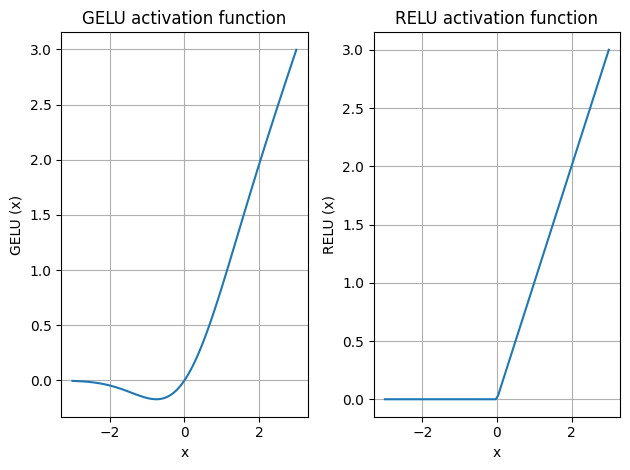

In [311]:
import matplotlib.pyplot as plt
gelu, relu = GeLU(), nn.ReLU()

x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "RELU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label} (x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [312]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layer = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GeLU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layer(x)

In [313]:
ffn = FeedForward(gpt_config_124M)
inp = torch.rand(2, 3, 768)
outp = ffn(inp)

In [314]:
outp.shape

torch.Size([2, 3, 768])

In [315]:
torch.arange(4)

tensor([0, 1, 2, 3])

## Adding Residual Connection

In [316]:
class ExampleNNBlock(nn.Module):
    def __init__(self, layer_sizes, use_residual):
        super().__init__()
        self.residual = use_residual
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GeLU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GeLU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GeLU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GeLU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GeLU()),
            
        ])

    def forward(self, x):
            for layer in self.layers:
                layer_output = layer(x)
                if self.residual and x.shape == layer_output.shape:
                    x = x + layer_output

                else:
                    x = layer_output

            return x
        

In [317]:
layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([1., 0., -1.])

model_without_shortcut = ExampleNNBlock(
    layer_sizes, False
)
model_with_shortcut = ExampleNNBlock(
    layer_sizes, True
)

In [318]:
def print_gradient(model, x):
    output = model(x)
    target = torch.tensor([0.])

    loss = nn.MSELoss()
    loss = loss(output, target)

    loss.backward()

    for name, param in model.named_parameters():
        if "weight" in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")
    

In [319]:
for name, param in model.named_parameters():
    print(name, param)

tok_emb.weight Parameter containing:
tensor([[ 0.5824, -0.4988, -0.1590,  ...,  0.0657,  1.3942, -0.2599],
        [-1.7458,  0.2840,  1.2488,  ...,  0.3805,  0.5114, -0.6442],
        [ 0.9109, -2.4539, -0.4278,  ...,  1.2542, -0.7258, -1.6545],
        ...,
        [ 0.2171,  1.0976,  0.7140,  ..., -1.9257, -0.8766,  0.5524],
        [ 1.0931,  0.7673, -1.1342,  ...,  0.5560, -2.9325, -0.1302],
        [-0.8089,  1.3225, -0.6154,  ..., -1.4366,  0.0354, -1.8273]],
       requires_grad=True)
pos_emb.weight Parameter containing:
tensor([[ 0.7792,  0.1384, -1.2545,  ...,  0.4007,  1.1804, -0.1016],
        [ 0.1802, -1.1870,  0.8701,  ...,  0.4128, -0.9669, -1.1560],
        [-1.8420,  0.1942, -0.0764,  ..., -0.7987, -0.3115,  1.2855],
        ...,
        [-0.5186, -0.9364, -0.5641,  ..., -0.4435, -0.2085, -0.6253],
        [-0.6573, -1.0300, -0.4178,  ...,  1.1026,  0.0800, -0.1296],
        [ 0.3146,  1.9623, -0.1536,  ..., -0.1734, -0.8041, -0.0463]],
       requires_grad=True)
out_

In [320]:
print_gradient(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.002343810396268964
layers.1.0.weight has gradient mean of 0.0017768084071576595
layers.2.0.weight has gradient mean of 0.0025916181039065123
layers.3.0.weight has gradient mean of 0.012994837015867233
layers.4.0.weight has gradient mean of 0.0344732403755188


In [321]:
print_gradient(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.42339274287223816
layers.1.0.weight has gradient mean of 0.4473041892051697
layers.2.0.weight has gradient mean of 0.36534583568573
layers.3.0.weight has gradient mean of 0.08642937988042831
layers.4.0.weight has gradient mean of 1.3505252599716187


## Transformer decode block

In [322]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.d_in = d_in
        self.d_out = d_out
        self.W_q = nn.Linear(d_in, d_out, qkv_bias)
        self.W_k = nn.Linear(d_in, d_out, qkv_bias)
        self.W_v = nn.Linear(d_in, d_out, qkv_bias)
        self.num_heads = num_heads
        self.dropout = nn.Dropout(dropout)
        self.head_dim = d_out // self.num_heads

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, inp_len, _ = x.shape
        query = self.W_q(x)
        key = self.W_k(x)
        value = self.W_v(x)

        query = query.view(b, inp_len, self.num_heads, self.head_dim)
        key = key.view(b, inp_len, self.num_heads, self.head_dim)
        value = value.view(b, inp_len, self.num_heads, self.head_dim)

        query = query.transpose(1, 2)
        key = key.transpose(1, 2)
        value = value.transpose(1, 2)

        attn_scores = query @ key.transpose(2, 3)
        masked = self.mask.bool()[:inp_len, :inp_len]
        masked_attn = attn_scores.masked_fill(masked, -torch.inf)

        attn_weights = torch.softmax(masked_attn/(keys.shape[-1]**0.5), dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_weights = (attn_weights @ value).transpose(1, 2)
        context_weights = context_weights.contiguous().view(b, inp_len, self.d_out)
        return context_weights
        
        

In [323]:
class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.attn = MultiHeadAttention(
            cfg["emb_dim"],
            cfg["emb_dim"],
            cfg["context_length"],
            cfg["drop_rate"],
            cfg["n_heads"],
            cfg["qkv_bias"]
        )
        self.ffn = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        # self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
        self.drop_shortcut_attn = nn.Dropout(cfg["drop_rate"])
        self.drop_shortcut_ffn = nn.Dropout(cfg["drop_rate"])
        

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.attn(x)
        x = self.drop_shortcut_attn(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ffn(x)
        x = self.drop_shortcut_ffn(x)
        x = x + shortcut

        return x

In [324]:
# gpt_config_124M
x = torch.rand(2, 4, 768)
transformer = DecoderBlock(gpt_config_124M)
op = transformer(x)

In [325]:
op.shape

torch.Size([2, 4, 768])

In [326]:
gpt_config_124M

{'vocab_size': 50257,
 'context_length': 1024,
 'emb_dim': 768,
 'n_heads': 12,
 'n_layers': 12,
 'drop_rate': 0.1,
 'qkv_bias': False,
 'drop_rate_gpt': 0.1,
 'drop_rate_decoder_ffn': 0.2,
 'drop_rate_decoder_attn': 0.2,
 'drop_rate_mha': 0.2}

In [327]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.token_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_block = nn.Sequential(
            *[DecoderBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, inp):
        batch_size, seq_len = inp.shape
        tok_embeds = self.token_emb(inp)
        pos_embed = self.pos_emb(torch.arange(seq_len, device=inp.device))

        x = tok_embeds + pos_embed
        x = self.drop_emb(x)
        x = self.trf_block(x)
        x = self.final_norm(x)
        logits = self.out_head(x)

        return logits

In [328]:
model = GPTModel(gpt_config_124M)
out = model(batch)

In [329]:
out

tensor([[[ 0.0603,  0.2231,  0.7122,  ...,  1.8244,  1.3781, -1.3808],
         [-0.7579, -0.3228,  0.9547,  ...,  1.3414,  1.5991, -0.2465],
         [-0.3742, -0.0599,  0.9366,  ...,  0.8566,  1.2034, -0.6112],
         [-0.6628, -0.0724,  1.8028,  ...,  1.1909,  1.1662, -0.8953],
         [-0.6207,  0.0220,  1.1878,  ...,  1.0525,  1.0204,  0.1126],
         [-0.2931,  0.2264,  0.8495,  ...,  1.1695,  0.6758, -0.7734]],

        [[-0.8284,  0.3581,  1.6473,  ...,  1.0275,  1.4958, -0.7036],
         [-0.9591,  0.5578,  1.1909,  ...,  0.8422,  1.0142, -0.6807],
         [-0.1481, -0.0494,  0.8520,  ...,  1.8108,  0.9351, -0.9241],
         [-0.5668,  0.7304,  0.9455,  ...,  1.5757,  1.4568, -1.0332],
         [-0.7461,  0.0951,  0.7131,  ...,  0.7930,  1.4240, -0.3722],
         [-0.3437,  0.2431,  0.2415,  ...,  1.3712,  0.8953, -0.7044]]],
       grad_fn=<UnsafeViewBackward0>)

In [330]:
total_params = sum(p.numel() for p in model.parameters())
print(total_params)

155922432


In [331]:
print(model.token_emb.weight.shape)
print(model.out_head.weight.shape)

torch.Size([50257, 768])
torch.Size([50257, 768])


In [332]:
total_size_bytes = total_params * 4
total_size_mb = total_size_bytes / (1024*1024)
print(total_size_mb)

594.796875


In [333]:
def model_configs_calc(cfg, device="cpu"):
    with torch.device(device):
        model=GPTModel(cfg)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total Parameters: {total_params}\n")
    total_size_bytes = total_params * 4
    total_size_mb = total_size_bytes / (1024*1024)
    print("Total Size:", total_size_mb)

In [334]:
gpt_mid = {'vocab_size': 50257,
 'context_length': 1024,
 'emb_dim': 1024,
 'n_heads': 16,
 'n_layers': 24,
 'drop_rate': 0.1,
 'qkv_bias': False}
print("GPT 2 Mid")
model_configs_calc(gpt_mid)

GPT 2 Mid
Total Parameters: 381022208

Total Size: 1453.484375


In [335]:
gpt_large = {'vocab_size': 50257,
 'context_length': 1024,
 'emb_dim': 1280,
 'n_heads': 20,
 'n_layers': 36,
 'drop_rate': 0.1,
 'qkv_bias': False}
print(f"GPT 2 Large")
model_configs_calc(gpt_large)

GPT 2 Large
Total Parameters: 779192320

Total Size: 2972.3828125


In [336]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

In [337]:
gpt_3 = {'vocab_size': 50257,
 'context_length': 2048,
 'emb_dim': 12288,
 'n_heads': 96,
 'n_layers': 96,
 'drop_rate': 0.1,
 'qkv_bias': False}
print(f"GPT 3")
# model_configs_calc(gpt_3, device)

GPT 3


## Generating Next Text

In [338]:
def generate_text(model, idx, max_new_token, context_size):
    for _ in range(max_new_token):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [339]:
start_context = "Hello, this is"
encode = tokenizer.encode(start_context)
encoded_batch = torch.tensor(encode).unsqueeze(0)
print(encoded_batch)
print(encoded_batch.size())

tensor([[15496,    11,   428,   318]])
torch.Size([1, 4])


In [340]:
model.eval()
out = generate_text(model, encoded_batch, 110, gpt_config_124M["context_length"])
out

tensor([[15496,    11,   428,   318, 34803,  8767, 34803, 34803, 34803, 34803,
         40196, 34803,  8767, 34803,  8767, 34803, 27839,  8767, 17440, 17440,
         34803,  8767,  8767, 17440, 34803, 34803, 40196,  8767,  8767,  8767,
         10538,  8767, 18474, 17440, 45778,  6171, 45778,  8767,  3975,  8767,
         18474, 39939, 34803,  8767, 25675, 25675, 34803, 34803, 27300,  8767,
         17440, 34803,  8767, 34803,  8767, 18474, 17440,  8767,  8767,  8767,
         10538,  8767, 10538,  8767, 25675,  8767, 33431,  8767,  8767, 18474,
         38175,  8767, 18474, 17440, 15663, 34803,  8767,  8767, 34803, 34803,
          8767, 10538,  8767, 18474, 17440, 10538, 24171, 34803, 27300,  8767,
         18474, 15663, 15663, 15663, 34803, 40196, 34803,  8767, 18474, 18474,
          8767, 17440, 34803,  8767, 34803,  8767, 34803, 34803, 40196,  8767,
         18474, 34803, 34803, 34803]])

In [341]:
deocde_text = tokenizer.decode(out.squeeze(0).tolist())
deocde_text

'Hello, this isîalysisîîîî Sharmaîalysisîalysisîutzalysisnodenodeîalysisalysisnodeîî Sharmaalysisalysisalysis burdenalysisCNNnode Continent syn Continentalysis mapalysisCNN poetsîalysis browse browseîîDefensealysisnodeîalysisîalysisCNNnodealysisalysisalysis burdenalysis burdenalysis browsealysis continentsalysisalysisCNNonomousalysisCNNnode tribesîalysisalysisîîalysis burdenalysisCNNnode burden assessingîDefensealysisCNN tribes tribes tribesî SharmaîalysisCNNCNNalysisnodeîalysisîalysisîî SharmaalysisCNNîîî'

# Ch-4 Pre-Training LLMs

In [342]:
gpt_config = {
    "vocab_size": 50257,
    "context_length": 256, #defaults to 1024
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

In [343]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flatten = token_ids.squeeze(0)
    return tokenizer.decode(flatten.tolist())

### Discovering Loss Function used during Pre-training

In [344]:
inputs = torch.tensor([[16833, 3626, 6100], [40, 1107, 588]]) 
# ["every effort moves",# "I really like"]

In [345]:
targets = torch.tensor([[3626, 6100, 345 ], # [" effort moves you",
[1107, 588, 11311]]) # " really like chocolate"]

In [346]:
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1)
print(probas.shape)
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("token ids shape", token_ids.shape)
print(token_ids)
print("Target Batch: ", token_ids_to_text(target[0].flatten(), tokenizer))
print("Predicted Batch: ", token_ids_to_text(token_ids[0].flatten(), tokenizer))

torch.Size([2, 3, 50257])
token ids shape torch.Size([2, 3, 1])
tensor([[[ 8767],
         [10019],
         [ 8767]],

        [[ 8767],
         [ 8767],
         [ 8767]]])
Target Batch:   cop conflic Ab true
Predicted Batch:  alysisNextalysis


In [347]:
print(f"Process of Cross Entropy")
text_ids = 0
target_probas1 = probas[text_ids, [0, 1, 2], targets[text_ids]]
print(f"Target Probability: {target_probas1}")

text_ids = 1
target_probas2 = probas[text_ids, [0, 1, 2], targets[text_ids]]
print(f"Target Probability: {target_probas2}")

log_probabs = torch.log(torch.cat((target_probas1, target_probas2)))
print(f"Log Probability: {log_probabs}")

avg_probabs = torch.mean(log_probabs)
print(f"Avg Probabs: {avg_probabs}")

avg_probabs = avg_probabs * (-1)
print(f"Negative Avg Probabs: {avg_probabs}") # we have to bring this down to 0

Process of Cross Entropy
Target Probability: tensor([1.3028e-05, 2.8407e-05, 1.5789e-05])
Target Probability: tensor([5.1263e-05, 5.9378e-05, 1.1413e-05])
Log Probability: tensor([-11.2484, -10.4689, -11.0562,  -9.8785,  -9.7316, -11.3807])
Avg Probabs: -10.627388954162598
Negative Avg Probabs: 10.627388954162598


In [348]:
# Using Pytorch for this
logits_flat = logits.flatten(0, 1)
target_flat = targets.flatten()
print(f'Flatten Logits: {logits_flat}')
print(f'Target Logits: {target_flat}')


Flatten Logits: tensor([[-0.3538,  0.7490,  1.6965,  ...,  1.7999,  2.1099, -0.8697],
        [-0.0094, -0.2605,  1.6074,  ...,  1.0421,  1.6751, -0.5984],
        [ 0.4044,  0.2603,  1.5268,  ...,  1.4395,  1.5508, -0.8170],
        [-0.5314,  0.0709,  0.6612,  ...,  1.1861,  1.2522, -0.8582],
        [-0.3276,  0.2308,  0.9339,  ...,  1.0291,  1.0811, -0.3695],
        [ 0.0035, -0.0768,  0.9056,  ...,  2.0328,  0.8514, -0.9467]])
Target Logits: tensor([ 3626,  6100,   345,  1107,   588, 11311])


In [349]:
loss = torch.nn.functional.cross_entropy(logits_flat, target_flat)
print(loss)
#perplexity
perplexity = torch.exp(loss)
print(perplexity)

tensor(10.6274)
tensor(41249.2812)


## Preparing Dataset (training and validation set)

In [350]:
file_path = "/kaggle/input/datasets/raaggeesingh/verdict-sample-dataset/the_verdict.txt"
with open(file_path, "r", encoding="utf-8") as f:
    file_text = f.read()

In [351]:
total_chars = len(file_text)
total_token_chars = len(tokenizer.encode(file_text))
print(total_chars)
print(total_token_chars)

20479
5145


In [352]:
train_ratio = 0.90
split_idx = int(train_ratio * len(file_text))
train_data = file_text[:split_idx]
val_data = file_text[split_idx:]

In [353]:
gpt_config_124M = {'vocab_size': 50257,
 'context_length': 256,
 'emb_dim': 768,
 'n_heads': 12,
 'n_layers': 12,
 'drop_rate': 0.1,
 'qkv_bias': False,
 'drop_rate_gpt': 0.1,
 'drop_rate_decoder_ffn': 0.2,
 'drop_rate_decoder_attn': 0.2,
 'drop_rate_mha': 0.2}
tokenizer = tiktoken.get_encoding("gpt2")
class GPTDatasetV1(Dataset):
    def __init__(self, tokenizer, max_length, stride, txt):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt)

        for i in range(0, len(token_ids)-max_length, stride):
            input_chunk = token_ids[i:i+max_length]
            target_chunk = token_ids[i+1:i+max_length+1]
            self.input_ids.append(input_chunk)
            self.target_ids.append(target_chunk)

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]
        
def create_dataloader_v1(txt, batch_size, stride=128, max_length=256, shuffle=True, drop_last=True):
    # toke = SimpleTokenizer(vocab)
    dataset = GPTDatasetV1(tokenizer, max_length, stride, txt)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        drop_last=drop_last,
    )
    return dataloader
    
train_loader = create_dataloader_v1(train_data, batch_size=2, stride=gpt_config_124M["context_length"], max_length=gpt_config_124M["context_length"])
val_loader = create_dataloader_v1(val_data, batch_size=2, stride=gpt_config_124M["context_length"], max_length=gpt_config_124M["context_length"])

In [354]:
print("Training Loader:")
for x, y in train_loader:
    x = torch.stack(x, dim=1)
    y = torch.stack(y, dim=1)
    print(x.shape, y.shape)

print("\nVal Loader:")
for x, y in val_loader:
    x = torch.stack(x, dim=1)
    y = torch.stack(y, dim=1)
    print(x.shape, y.shape)

Training Loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Val Loader:
torch.Size([2, 256]) torch.Size([2, 256])


In [355]:
gpt_config_124M

{'vocab_size': 50257,
 'context_length': 256,
 'emb_dim': 768,
 'n_heads': 12,
 'n_layers': 12,
 'drop_rate': 0.1,
 'qkv_bias': False,
 'drop_rate_gpt': 0.1,
 'drop_rate_decoder_ffn': 0.2,
 'drop_rate_decoder_attn': 0.2,
 'drop_rate_mha': 0.2}

In [356]:
def calc_loss_batch(input_batch, target_batch, devices, model):
    if isinstance(input_batch, list):
        input_batch = torch.stack(input_batch, dim=1)
        target_batch = torch.stack(target_batch, dim=1)
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)

    pred = model(input_batch)
    loss = torch.nn.functional.cross_entropy(pred.flatten(0, 1), target_batch.flatten())
    return loss

In [357]:
def calc_loss_loader(data_loader, model, num_batch, device):
    total_loss = 0
    if len(data_loader) == 0:
        return

    elif num_batch == 0:
        num_batch == len(data_loader)

    else:
        num_batch = min(num_batch, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batch:
            input_batch = torch.stack(input_batch, dim=1)
            target_batch = torch.stack(target_batch, dim=1)
            
            loss = calc_loss_batch(input_batch, target_batch, device, model)
            total_loss += loss.item()

        else:
            break

    return total_loss/num_batch

In [358]:
devices = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, num_batch=2, device=device)
    val_loss = calc_loss_loader(val_loader, model, num_batch=2, device=device)
print("Train Loss", train_loss)
print("Val Loss", val_loss)

Train Loss 11.112546920776367
Val Loss 11.069629669189453


## Training Loop

In [359]:
def training_loop(model, train_loader, val_loader, optimizer, device, num_epochs,
                 eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_token_seen = [], [], []
    token_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(input_batch, target_batch, device, model)
            loss.backward()
            optimizer.step()

            token_seen += 1
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_losses)
                track_token_seen.append(token_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                    f"Train loss {train_loss:.3f}, "
                    f"Val loss {val_loss:.3f}"
                )

        generate_and_print(model, tokenizer, device, start_context)

    
    
    return train_losses, val_losses, track_token_seen

In [360]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, eval_iter, device)
        val_loss = calc_loss_loader(val_loader, model, eval_iter, device)

    model.train()
    return train_loss, val_loss
        

In [363]:
def generate_and_print(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encode = text_to_token_ids(start_context, tokenizer).to(device)

    with torch.no_grad():
        token_ids = generate_text(model, encode, 10, context_size)
        
    decoder_text = token_ids_to_text(token_ids, tokenizer)
    print(decoder_text)
    model.train()

In [ ]:
model = GPTModel(gpt_config_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.004, weight_decay=0.1)
num_epochs = 10

train_loss, val_loss = training_loop(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq=5, 
                                     eval_iter=5, start_context="Hey. My name is", tokenizer=tokenizer)
print(train_loss, val_loss)

Ep 1 (Step 000000): Train loss 8.212, Val loss 8.583
Ep 1 (Step 000005): Train loss 7.542, Val loss 9.224
Hey. My name is I I I I I I I I I I
Ep 2 (Step 000010): Train loss 7.593, Val loss 7.722
Ep 2 (Step 000015): Train loss 6.908, Val loss 8.304
Hey. My name is










Ep 3 (Step 000020): Train loss 6.732, Val loss 7.966
Ep 3 (Step 000025): Train loss 6.330, Val loss 7.713
Hey. My name is the the the the the the the the the the
Ep 4 (Step 000030): Train loss 6.341, Val loss 7.648
Ep 4 (Step 000035): Train loss 6.565, Val loss 7.845
Hey. My name is,,,,,,,,,,
